# Sparse Rewiring: Interpreting Surviving `down_proj` Vectors with Logit Lens, J-Lens, J++, and R-Lens

**Base model:** `Qwen/Qwen2.5-1.5B-Instruct` (28 layers, `d_model = 1536`, `d_mlp = 8960`)  
**Pre-fitted lenses:** `neuronpedia/jacobian-lens` (`qwen2.5-1.5b-it/{jlens,jpp,rlens}`, `capture_point = block_output`, `L0–L26`; `L27 = identity`)

Because `down_proj` stayed **frozen** during sparse L0 rewiring, each surviving neuron can only steer the residual stream along its pre-existing output column $v_j = W_{\text{down}}^{(L)}[:, j]$.

**Groups analyzed (18 unique neurons across both arms):**
- **Shared (5):** `L11 #8235`, `L16 #5569`, `L17 #6230`, `L17 #7054`, `L19 #5606`
- **Rank 0 only (7):** `L3 #574`, `L4 #1398`, `L6 #1362`, `L12 #6760`, `L18 #4890`, `L27 #4914`, `L27 #7926`
- **Rank 1 only (6):** `L2 #4005`, `L6 #5466`, `L14 #3925`, `L26 #8751`, `L27 #1683`, `L27 #6214`

> **Fast iteration:** All 18 × 4 decoded vocab logit vectors and transported J-space vectors are cached in `cache/down_proj_decoded.pt` (~25 MB), so re-running any analysis, table, or plot below takes **~1–2 seconds** without reloading the model or lenses.


In [1]:
import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

os.environ.setdefault("MPLCONFIGDIR", "/tmp/mpl_cache")
plt.rcParams["figure.dpi"] = 140
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 220)

CACHE_PATH = "cache/down_proj_decoded.pt"
FIG_DIR = "cache/figures"
os.makedirs(FIG_DIR, exist_ok=True)

data = torch.load(CACHE_PATH, map_location="cpu", weights_only=False)
SURVIVORS = data["survivors"]
LENS_NAMES = data["lens_names"]  # ['logit_lens', 'jlens', 'jpp', 'rlens']
ID_TO_STR = data["id_to_str"]
RAW_V = data["raw_v"].float()                           # [18, 1536]
TRANS_U = {k: v.float() for k, v in data["transported_u"].items()}  # each [18, 1536]
U_RAW_NORMS = {k: v.float() for k, v in data["u_raw_norms"].items()}
LOGITS = {k: v.float() for k, v in data["logits_fp16"].items()}     # each [18, 151936]
TOP_K_RECS = data["top_k_records"]
LAYER_STATS = data["layer_norm_stats"]

# Adjustable knob for fast iteration:
TOP_K = 10

LABELS = [s["label"] for s in SURVIVORS]
GROUPS = [s["group"] for s in SURVIVORS]
IDX_SHARED = [i for i, s in enumerate(SURVIVORS) if s["group"] == "shared"]
IDX_R0_ONLY = [i for i, s in enumerate(SURVIVORS) if s["group"] == "r0_only"]
IDX_R1_ONLY = [i for i, s in enumerate(SURVIVORS) if s["group"] == "r1_only"]
IDX_R0_ALL = [i for i, s in enumerate(SURVIVORS) if s["in_r0"]]
IDX_R1_ALL = [i for i, s in enumerate(SURVIVORS) if s["in_r1"]]

print(f"Loaded cache: {CACHE_PATH} ({os.path.getsize(CACHE_PATH)/1e6:.2f} MB)")
print(f"Model: {data['model_id']} | Lenses: {LENS_NAMES} | Vocab: {len(ID_TO_STR):,}")
print(f"Counts -> Shared: {len(IDX_SHARED)} | R0 only: {len(IDX_R0_ONLY)} | R1 only: {len(IDX_R1_ONLY)} | Total unique: {len(SURVIVORS)}")

def clean_tok(s: str) -> str:
    return repr(s)

def fmt_top(lens_name: str, neuron_i: int, pole: str = "pos", k: int = TOP_K) -> str:
    items = TOP_K_RECS[lens_name][neuron_i][pole][:k]
    return ", ".join(clean_tok(tok_str) for _, tok_str, _ in items)

def cosine_matrix(X: torch.Tensor) -> np.ndarray:
    Xn = X / (X.norm(dim=-1, keepdim=True) + 1e-8)
    return (Xn @ Xn.T).numpy()


Loaded cache: cache/down_proj_decoded.pt (25.05 MB)
Model: Qwen/Qwen2.5-1.5B-Instruct | Lenses: ['logit_lens', 'jlens', 'jpp', 'rlens'] | Vocab: 151,936
Counts -> Shared: 5 | R0 only: 7 | R1 only: 6 | Total unique: 18


In [2]:
# Check whether L0 sparse rewiring selects unusually high-norm down_proj neurons,
# and inspect the transport gain ||J_L v|| / ||v|| across all 3 J-lens variants.
rows = []
for i, s in enumerate(SURVIVORS):
    L = s["layer"]
    vn = s["v_norm"]
    st = LAYER_STATS[L]
    rows.append({
        "group": s["group"],
        "neuron": s["label"],
        "layer": L,
        "v_norm": round(vn, 3),
        "layer_med": round(st["median"], 3),
        "norm_pct": round(s["v_norm_pct"], 1),
        "gain_jlens": round(float(U_RAW_NORMS["jlens"][i]) / vn, 2),
        "gain_jpp": round(float(U_RAW_NORMS["jpp"][i]) / vn, 2),
        "gain_rlens": round(float(U_RAW_NORMS["rlens"][i]) / vn, 2),
    })

df_norms = pd.DataFrame(rows)
display(df_norms)

print("\nMean down_proj norm percentile by group:")
print(df_norms.groupby("group")["norm_pct"].agg(["count", "mean", "median", "min", "max"]).round(1))
print("\nNote: At L27, J = I so gain = 1.00 across all lenses. Watch L26 jpp gain (J++ filters heavily at L26).")



Mean down_proj norm percentile by group:
         count  mean  median  min   max
group                                  
r0_only      7  26.3    18.9  1.9  87.8
r1_only      6  32.0     8.6  0.6  94.3
shared       5  37.5    50.9  1.2  78.1

Note: At L27, J = I so gain = 1.00 across all lenses. Watch L26 jpp gain (J++ filters heavily at L26).


,group,neuron,layer,v_norm,layer_med,norm_pct,gain_jlens,gain_jpp,gain_rlens
0,shared,L11 #8235,11,0.779,1.023,1.5,1.48,1.19,1.44
1,shared,L16 #5569,16,1.020,1.008,55.7,3.17,1.35,1.86
2,shared,L17 #6230,17,1.105,1.042,78.1,0.80,0.82,0.98
3,shared,L17 #7054,17,1.044,1.042,50.9,0.91,0.82,0.94
4,shared,L19 #5606,19,0.808,1.071,1.2,2.70,1.71,1.92
5,r0_only,L3 #574,3,0.970,1.026,35.1,0.81,0.87,1.39
6,r0_only,L4 #1398,4,0.937,1.005,18.9,0.60,0.65,0.90
7,r0_only,L6 #1362,6,0.862,1.068,1.9,0.46,0.98,0.60
8,r0_only,L12 #6760,12,1.147,1.032,87.8,2.29,2.51,1.93
9,r0_only,L18 #4890,18,0.980,1.048,27.1,1.71,0.49,1.49


In [3]:
# Precompute logit-space cosine matrix under J++ (and R-Lens) to annotate each rank-only
# neuron with its closest match in the opposite arm.
COS_LOGITS = {ln: cosine_matrix(LOGITS[ln]) for ln in LENS_NAMES}
COS_RAW = cosine_matrix(RAW_V)

def closest_in_other_arm(i: int, lens_name: str = "rlens") -> str:
    s = SURVIVORS[i]
    if s["group"] == "shared":
        return "—"
    other_idxs = IDX_R1_ALL if s["group"] == "r0_only" else IDX_R0_ALL
    C = COS_LOGITS[lens_name]
    best_j = max(other_idxs, key=lambda j: abs(C[i, j]))
    return f"{LABELS[best_j]} ({C[i, best_j]:+.2f})"

def build_group_table(indices, title: str, k: int = TOP_K):
    display(Markdown(f"## {title}"))
    rows = []
    for i in indices:
        s = SURVIVORS[i]
        # Agreement between jlens, jpp, rlens in logit space
        ag_jr = COS_LOGITS["jlens"][i, i] # dummy
        c_jl_jp = float(torch.nn.functional.cosine_similarity(LOGITS["jlens"][i], LOGITS["jpp"][i], dim=0))
        c_jl_rl = float(torch.nn.functional.cosine_similarity(LOGITS["jlens"][i], LOGITS["rlens"][i], dim=0))
        c_jp_rl = float(torch.nn.functional.cosine_similarity(LOGITS["jpp"][i], LOGITS["rlens"][i], dim=0))
        c_ll_rl = float(torch.nn.functional.cosine_similarity(LOGITS["logit_lens"][i], LOGITS["rlens"][i], dim=0))

        row_pos = {
            "Neuron": s["label"],
            "Pole": "+v (promote)",
            "Norm %ile": f"{s['v_norm_pct']:.1f}%",
            "Logit Lens": fmt_top("logit_lens", i, "pos", k),
            "J-Lens": fmt_top("jlens", i, "pos", k),
            "J++": fmt_top("jpp", i, "pos", k),
            "R-Lens": fmt_top("rlens", i, "pos", k),
            "cos(J,J++,R)": f"{c_jl_jp:.2f} / {c_jl_rl:.2f} / {c_jp_rl:.2f}",
            "Closest other arm (R-Lens)": closest_in_other_arm(i, "rlens"),
        }
        row_neg = {
            "Neuron": s["label"],
            "Pole": "-v (suppress / neg act)",
            "Norm %ile": f"(LL↔R: {c_ll_rl:.2f})",
            "Logit Lens": fmt_top("logit_lens", i, "neg", k),
            "J-Lens": fmt_top("jlens", i, "neg", k),
            "J++": fmt_top("jpp", i, "neg", k),
            "R-Lens": fmt_top("rlens", i, "neg", k),
            "cos(J,J++,R)": "",
            "Closest other arm (R-Lens)": "",
        }
        rows.extend([row_pos, row_neg])
    df = pd.DataFrame(rows)
    display(df)
    return df


In [4]:
df_shared = build_group_table(IDX_SHARED, "1. Shared Neurons (5) — Kept by BOTH Rank 0 and Rank 1 (all in L11–L19)")


## 1. Shared Neurons (5) — Kept by BOTH Rank 0 and Rank 1 (all in L11–L19)

,Neuron,Pole,Norm %ile,Logit Lens,J-Lens,J++,R-Lens,"cos(J,J++,R)",Closest other arm (R-Lens)
0,L11 #8235,+v (promote),1.5%,"'随便', '下面就', '屁股', '便可', ' wont', 'iks', 'ILITIES', 'orent', ' Blacks', '-points'","'......', '.....', ' (', '...', '....', ' ....', ' ...', '--', ' .....', '.......'","' ,', ' --', ' @', ' .', ' ,,', ' ;', ' \xa0', ' !', ' _', ' ,('","' (', '\xa0', '\xa0\xa0\xa0\xa0\xa0\xa0\xa0\xa0', ' --', ' “', '\xa0\xa0\xa0\xa0', ' presently', '\xa0\xa0\xa0', ' [', ' \xa0'",0.69 / 0.84 / 0.89,—
1,L11 #8235,-v (suppress / neg act),(LL↔R: 0.43),"' erf', '国道', '[mid', '道士', 'Fizz', '🌍', '门前', 'traction', 'HING', 'potential'","'）\n\n', '）\n', '】\n\n', '）\r\n', '""""""\r\n\r\n', '""""""\r\n', '"")\r\n\r\n', '""]\r\n', '""""""\n\n\n', '？\n'","'?"")\n', ':"")\n', '?"",', ':"");\r\n', '."")\r\n', '?"");\n', ':"");\n', '确保', '高昂', '""):\r\n'","'？\n\n', '？\n', '确保', '](\n', '展现出', '\n \n', '可能', '可能会', '社交媒体', '相较于'",,
2,L16 #5569,+v (promote),55.7%,"' Spi', '盅', 'gil', '放下', '/mp', ' drummer', ' Blackjack', ' Bruins', ' Moo', '踽'","' (\\<', ' [*', ' [`', '):\r\n\r\n', '[*', '--[', ':**', ' (`', ':\r\n\r\n', ' [_'","'\xa0\n', '\xa0', '%\r\n', '\xa0\xa0\xa0\xa0\xa0\xa0\xa0\xa0', '\r\n', ':]\n', ' \xa0 \xa0 \xa0 \xa0', '\xa0\xa0\xa0\xa0\xa0\xa0\xa0', '...","'):\n\n', ' [*', ':"");\n\n', ':\n\n', ':\r\n\r\n', '):\r\n\r\n', ':"");\n', ' (\\<', '"":\n\n', '[*'",0.53 / 0.84 / 0.73,—
3,L16 #5569,-v (suppress / neg act),(LL↔R: 0.49),"'原标题', '<|endoftext|>', ' ()\n', '()""\n', ""''\n"", "" ''\n"", '”\n', '返回搜狐', '``\n', '""\n'","'”\n', '”\n\n', '）\n', '？\n', ' ohio', '\xa0\n', '\n', '""\n', '\ufeff\n', ' .\n'","' nothing', ' nobody', ' whats', 'htags', ' place', ' yeah', ' what', ' anybody', ' thing', ' god'","'<|endoftext|>', '”\n', ' \u200b\u200b', '\n\n\n\n\n', ' doesnt', '）\n', '\n\n\n', ' didnt', ""'\n\n\n"", '’\n\n'",,
4,L17 #6230,+v (promote),78.1%,"'=""__', 'ʕ', ' Feel', '裘', 'IED', ' ITS', 'outu', '伋', 'ZO', 'PRI'","'>\\', ' ≠', '确实', ' *__', ' :\\', ' ≥', '≥', '确', '=\\""', '):\\'","'里程', ' honoring', ' titled', ' Visible', '真实', '的真实性', 'Actual', '绶', 'Appear', '真实性'","'的真实性', '我能', ' ≠', '我也', '确实', '我不', ' ≥', '我真的', '(True', '真实性'",0.62 / 0.85 / 0.78,—
5,L17 #6230,-v (suppress / neg act),(LL↔R: 0.66),"'serter', '是我国', 'otas', 'due', 'бит', '是中国', '二十五', '介质', 'oin', 'lator'","' malformed', ' cuckold', '颓', '[\n', ' stagn', '紊乱', ' destabil', '\n', ' reform', ' rebuilt'","'?\n\n\n', '第三次', '…\n\n\n', '?\n\n\n\n', '?\n\n\n\n\n\n', ' contraceptive', '!\n\n\n', '/\n\n\n', '紊乱', ' cuckold'","'由於', 'rowsers', '紊乱', 'jähr', ' contraceptive', '蒿', '\')}}""></', '最常见的', ' reforms', ' reform'",,
6,L17 #7054,+v (promote),50.9%,"'irse', 'möglich', ' resort', '/{{', '大的', ':;\n', ' unterstüt', 'erra', '下来的', 'orca'","' \\<', ' :\n\n', ' ;\n\n', '__;\n', '::\n\n', '\\<', ' *\\', '\\.', ' ;\r\n\r\n', '\\['","'/,', 'ключа', '__;', '!,', '(""/"")', ' @(', ' ready', ' prêt', '__,', '.@'","' ;\n\n', ' :\n\n', ' ;\r\n\r\n', '__;\n', ' .\n\n', '##\n\n', ' ;\n', ' \n\n', ' *\\', ' ;'",0.50 / 0.82 / 0.73,—
7,L17 #7054,-v (suppress / neg act),(LL↔R: 0.66),"'otted', 'ataka', '特别声明', 'dan', 'estroy', ' Set', 'urst', 'SETTING', '终生', 'ser'","'…”', '…)', '…\n', ' […', '…""', '…”\n\n', ' […]', '…I', '…', '…""\n\n'","'序', '女友', '-cols', '男友', 'itti', 'ctrine', 'SEQ', '特别声明', 'ographer', '新陈'","'…”', '…)', '…I', '…it', '…and', '…the', '…\n', '…)\n\n', '…""', '…'",,
8,L19 #5606,+v (promote),1.2%,"'____', ' ______', ' ____', ' ___', ' __', ' _____', ' __________________', '________', '________________', '____________'","' __', ' ____', ' ___', ' ______', '____', ' _____', ' __________________', '____________', '________', '_____'","' __', ' ____', ' ______', ' ___', '____', ' _____', ' __________________', '____________', '________________', '_____'","' __', ' ____', ' ______', ' ___', '____', ' _____', ' __________________', '________', '____________', '_____'",0.89 / 0.93 / 0.98,—
9,L19 #5606,-v (suppress / neg act),(LL↔R: 0.73),"',', '<|endoftext|>', 

In [5]:
df_r0_only = build_group_table(IDX_R0_ONLY, "2. Rank 0 Only Neurons (7) — Unconstrained Delta Only")


## 2. Rank 0 Only Neurons (7) — Unconstrained Delta Only

,Neuron,Pole,Norm %ile,Logit Lens,J-Lens,J++,R-Lens,"cos(J,J++,R)",Closest other arm (R-Lens)
0,L3 #574,+v (promote),35.1%,"'蚕', ' Directions', ' bàn', ' CONTRIBUT', ' brings', 'upal', 'Filed', ' flor', 'ull', 'стал'","'"",[', '.""[', ').[', '""):\r\n', '"").\n\n', '"".\n\n', '""—', '"":\r\n', ')—', '[""+'","'数学', ' Maths', '花朵', ' maths', '老师', ' rozwiązania', '呢', '情境', '汁', '图形'","'数学', '？\n\n', '老师', '花朵', '教师', ' Maths', '呢', '""?\n\n', '儿童', '一定'",0.49 / 0.56 / 0.97,L11 #8235 (-0.54)
1,L3 #574,-v (suppress / neg act),(LL↔R: 0.13),"'nonnull', 'erah', 'endcode', '🥰', '託', '*e', ' Wa', '_ENSURE', '貫', '-house'",""" '\n"", ' »', ' |\n', ' \n', ""'\n"", ' *\n', ' -\n', ' !\n', "" ',\n"", ' `\n'","' aboard', ' tele', ' prior', ' Reich', ' Tele', ' early', ' ship', ' reportedly', ' Hell', ' Naval'","' prior', ' aboard', ' U', ' reportedly', ' tele', ' Hell', ' later', ' —', ' former', ' Tele'",,
2,L4 #1398,+v (promote),18.9%,"'unders', ' SharePoint', ' PowerPoint', ' groom', '龙湖', '金山', ' Pra', 'azure', 'Azure', '燧'","'…”', '…”\n\n', '”—', '?”\n\n', '?”', ' …\n\n', '…\n\n', '…""\n\n', '”\n\n', '…""'","' SharePoint', '.microsoft', ' PowerShell', 'Microsoft', '服务器', ' Microsoft', ' Workflow', ' VMware', ' Server', 'Servers'","' SharePoint', '客户需求', ' Workflow', ' workflow', 'Workflow', ' workflows', '为客户', ' PowerShell', 'SQL', '.microsoft'",0.52 / 0.65 / 0.87,L2 #4005 (-0.17)
3,L4 #1398,-v (suppress / neg act),(LL↔R: 0.28),"'ofile', 'rades', '钍', 'icy', 'FML', ' gesture', 'ifr', 'gesture', ' Dzięki', '⽀'","'「', '。「', "" '\\\\"", ' :\\', ' ``', '、「', ' apologise', '。\\', ' \\""{', "" '\\\\'""","' motorcycle', '摩托车', ' bicycle', ' rehabilitation', ' honda', ' Costa', '秕', ' coconut', '自行车', ' raped'","' kak', ' essay', ' bourgeois', 'argent', ' capitalist', ' criticised', ' feminism', ' afterwards', ' punishments', ' dictatorship'",,
4,L6 #1362,+v (promote),1.9%,"'�认', 'marca', '喙', '会让你', '他会', 'ptest', '!!"");\n', '(*)(', 'xCC', '-clock'","',”', ')”', '?”', '.”', '!”', '？”', '."",\r\n', '”—', '”?', '”'","' shipments', '馕', ' bú', 'departure', '进口', '郊', '饮酒', ' pallet', '鹛', 'ixture'","'-BEGIN', '不合格', '-placement', '-shopping', ' shipments', '-import', '-INF', '-describedby', '-scalable', '-unused'",0.36 / 0.49 / 0.83,L14 #3925 (+0.39)
5,L6 #1362,-v (suppress / neg act),(LL↔R: 0.19),"'\n', '�', '坐', '\r\n', '贱', '溢', 'jer', '挨', 'erals', ':'","'...\n', '...\n\n', ',...\n', '....\n', ' ...\n', '\xa0\n', '......\n\n', '...\n\n\n', '....\n\n', '...\n\n\n\n'","':\n\n', ':\n', ':\n\n\n', ""'''\n\n"", ""':\n\n"", ' Wiki', '是我的', ""'''\n"", ' 🙂\n\n', '...\n\n'","'...\n\n', ' ...\n\n', '...\n', '...\n\n\n', ' ...\n', '...\n\n\n\n', ' …\n\n', '....\n\n', ' ..\n\n', ' ....\n\n'",,
6,L12 #6760,+v (promote),87.8%,"' Por', 'culate', 'cdc', ' }),\n\n', ' getCode', ',...\n\n', 'unded', ' Burr', ' expose', '~\n\n'","'\xa0', '\xa0\xa0', '\xa0\xa0\xa0\xa0\xa0\xa0\xa0\xa0', '\xa0\xa0\xa0\xa0', '\xa0\xa0\xa0', ' \xa0', '\xa0\xa0\xa0\xa0\xa0\xa0\xa0', ' \...","'穆', ' Libyan', '狄', '铀', 'ISIS', 'mdb', '阿富汗', '镍', '镭', '留学'","'\xa0', '\xa0\xa0', '\xa0\xa0\xa0\xa0\xa0\xa0\xa0\xa0', '\xa0\xa0\xa0\xa0', '\xa0\xa0\xa0', ' \xa0', ' \xa0 \xa0 \xa0 \xa0', '\xa0\xa0\x...",0.37 / 0.94 / 0.51,L6 #5466 (+0.66)
7,L12 #6760,-v (suppress / neg act),(LL↔R: 0.44),"'manship', ' Ada', ' fwd', '.lastname', 'agr', 'threads', 'central', '声明', 'leaf', 'membership'","'\n \n', '<\\/', '\\/', '.\n', ':\\/\\/', '!\n', '?\n', '。\n', '..\n', '\r\n\t\r\n'","'\xa0', '\xa0\n', '\xa0\xa0', '\xa0\xa0\xa0', ' \xa0', '\xa0\xa0\xa0\xa0', '\xa0\xa0\xa0\xa0\xa0\xa0\xa0', 'manship', ' \xa0 \xa0', ' La...","'\\/', '<\\/', ':\\/\\/', '\n \n', '\r\n\t\r\n', '.\n', ' \\/', '\\/\\/', 'firstname', ' firstname'",,
8,L18 #4890,+v (promote),27.1%,"'.\n', '().\n', '。\n', '/.\n', ' .\n', '？\n', '?\n', '!\n', ""'.\n"", ' ?\n'","'.\n', ';\n', '。\n', '?\n', ' .\n', '!\n', '；\n', ',\n', '？\n', ' ?\n'","' \\\r\n', ' \r\n', ' \r\n', ' \r\n', '**\r\n', ' |\r\n', '.\\""', '\\\r\n', '\r\n\r\n\r\n', ' """"""\

In [6]:
df_r1_only = build_group_table(IDX_R1_ONLY, "3. Rank 1 Only Neurons (6) — Layer-Shared Read Direction Only")


## 3. Rank 1 Only Neurons (6) — Layer-Shared Read Direction Only

,Neuron,Pole,Norm %ile,Logit Lens,J-Lens,J++,R-Lens,"cos(J,J++,R)",Closest other arm (R-Lens)
0,L2 #4005,+v (promote),0.6%,"'سمي', 'kul', 'ndon', '—are', '。「', 'ớ', 'EEP', 'ipel', '橐', ':@""%@'","'–', '.–', ' –', '.', '–and', ')—', '●', '•', ' •', '....\n'","'--)', ' ).\n\n', ' herself', ' themselves', ' himself', ').\n\n', '也不可能', '.)\n\n', ').(', '只不过是'","' ).\n\n', ').""', '.)\n\n', '.).\n\n', ' );', ').\n\n', ' ).', ' )\n\n', "").'"", ' =\n\n'",0.17 / 0.28 / 0.94,L3 #574 (-0.34)
1,L2 #4005,-v (suppress / neg act),(LL↔R: 0.18),"'Ix', 'dat', 'hear', 'heid', 'bilt', ' dat', 'ocaust', 'her', '*****\n', 'dba'","' ``(', ' ``', "".''\n\n"", '？\n\n', '``,', '（', '！\n\n', '）\n\n', '：</', '）\r\n'","' �', '=https', ' https', 'https', ' �', ' COVID', ' �', '""https', '""+\n', 'COVID'","'=https', '：\n', 'https', '\\\r\n', '”\n', ' \\\r\n', ' �', ' https', '咱们', '\\\n'",,
2,L6 #5466,+v (promote),78.9%,"' Mü', 'dom', 'DOM', 'URITY', 'AIN', 'AINS', 'NavController', 'ube', ' domestic', 'nut'","'\n\n', '--\n\n', '—\n\n', ',\n\n', '-\n\n', ' \n\n', ' \n\n', '!\n\n', '.\n\n', '：\n\n'","'(Database', 'AndHashCode', '.djangoproject', '留守', ' Dul', '叽', 'McC', ' muff', ' McCartney', '.Toolkit'","'--\n\n', '\n\n', '—\n\n', ',\n\n', '：\n\n', '-\n\n', '？\n\n', '，\n\n', '。\n\n', '!\n\n'",0.50 / 0.95 / 0.62,L12 #6760 (+0.66)
3,L6 #5466,-v (suppress / neg act),(LL↔R: 0.41),"'threads', '髹', 'сь', 'aland', '(:,:,', 'quist', 'ше', ' Alam', 'ship', 'Double'","'.”\n', '.\n', '…\n', '”\n', '?\n', ' ..\n', '..\n', ')\n', '!\n', '.)\n'","' Boca', ' LG', 'ty', ' Aviv', 'tls', 'izr', ' samsung', 'ld', ' ws', '德州'","'.”\n', '.\n', ' .\n', ')\n', '..\n', '”\n', "".'\n"", '.)\n', ').\n', '!\n'",,
4,L14 #3925,+v (promote),94.3%,"'[value', 'mage', '[dim', '/hash', 'trimmed', 'HITE', 'sdale', ' mails', '[url', '.dimension'","'\xa0', '\xa0\xa0\xa0\xa0\xa0\xa0\xa0', '\xa0\xa0', '\xa0\xa0\xa0\xa0', '\xa0\xa0\xa0\xa0\xa0\xa0\xa0\xa0', '\xa0\xa0\xa0', ':\\', '):\\...","' favourites', ' favourite', '内地', ' daß', 'áz', ' btnCancel', '家长', ' borderTop', '新城', '学费'","'\xa0', ':"");\r\n', ':"");\n', ' favourites', '\xa0\xa0\xa0\xa0\xa0\xa0\xa0', '\xa0\xa0\xa0\xa0', '\xa0\xa0\xa0\xa0\xa0\xa0\xa0\xa0', ' f...",0.62 / 0.84 / 0.81,L6 #1362 (+0.39)
5,L14 #3925,-v (suppress / neg act),(LL↔R: 0.34),"'结', ' st', '情况', ' &', '特', '获', ' fmt', '盎', '提起', '第'","' \n\n', ' \n', '\n \n', ' \n \n', ' …\n\n', '...\n\n', '...\n', ' \n \n', ' \n', ' \n\n\n'","'..."",\n', '...""\n\n', ' \\\n', '...""\n', '...', '...""', ' ...""\n\n', ' ...', ' ...""\n', '...\n\n'","' \n\n', ' ...\n\n', '...\n\n', ' …\n\n', '...""\n\n', '...\n\n\n\n\n\n', ' \n', '...\n\n\n', ' ...\n', ' ...""\n\n'",,
6,L26 #8751,+v (promote),10.3%,"' Left', ' left', 'left', 'Left', 'Shown', '_left', ' Done', '\tdone', ' form', '-left'","' Left', ' left', 'left', ' Done', ' form', 'Left', 'Shown', '\tdone', '_left', ' Held'","'ensor', 'izacion', 'zo', ' Jad', 'omatic', 'alten', 'cin', 'ensors', ' dismiss', 'タン'","' Left', ' left', 'left', 'Left', 'Shown', ' Done', ' form', '_left', '\tdone', 'izando'",0.77 / 0.99 / 0.77,L27 #7926 (+0.13)
7,L26 #8751,-v (suppress / neg act),(LL↔R: 0.99),"' hur', ' h', '物', 'ega', '色', ' ste', '(Type', 'wię', ' lo', '=h'","' hur', '物', ' h', '色', 'ega', '正', '(Type', '=h', '.Magenta', '背'","' hur', 'yi', 'ntag', '=Value', 'ITIONAL', 'outu', '物', 'geries', '➜', 'YRO'","' hur', ' h', '物', 'ega', '色', '(Type', '=h', 'wię', '辟', '釜'",,
8,L27 #1683,+v (promote),1.3%,"' yg', ' hb', ' hf', ' stm', ' nf', ' stk', ' gd', ' Sexo', ' rl', ' pll'","' yg', ' hb', ' hf', ' stm', ' nf', ' stk', ' gd', ' Sexo', ' rl', ' pll'","' yg', ' hb', ' hf', ' stm', ' nf', ' stk', ' gd', ' Sexo', ' rl', ' pll'","' yg', ' hb', ' hf', ' stm', ' nf', ' stk', ' gd', ' Sexo', ' rl', ' pll'",1.00 / 1.00 / 1.00,L3 #574 (+0.40)
9,L27 #1683,-v (suppress / neg act),(LL↔R: 1.00),"'用微信扫', 'крат', ' cher', ' arch', ' wid', 'auważ', 'lığa', ' kn', '-ton', ' pewnością'","'用微信扫', 'крат', ' cher', ' arch', ' wid', 'auważ', 'lığa', ' kn', '-to

In [7]:
display(Markdown("## 4. Full-Arm Comparison: Rank 0 (12 neurons) vs. Rank 1 (11 neurons)"))

def participation_ratio(X: torch.Tensor) -> float:
    # Effective rank / participation ratio of rows of X (mirror of Section 6 in the PDF)
    s = torch.linalg.svdvals(X.float())
    lam = s ** 2
    return float((lam.sum() ** 2) / (lam.pow(2).sum() + 1e-12))

def dirs_for_90pct(X: torch.Tensor) -> int:
    s = torch.linalg.svdvals(X.float())
    cum = torch.cumsum(s ** 2, dim=0) / (s ** 2).sum()
    return int((cum < 0.90).sum().item()) + 1

def subspace_overlap(X1: torch.Tensor, X2: torch.Tensor) -> dict:
    # Principal angles between span(X1) and span(X2) via SVD of Q1^T Q2
    Q1, _ = torch.linalg.qr(X1.T.float())
    Q2, _ = torch.linalg.qr(X2.T.float())
    sv = torch.linalg.svdvals(Q1.T @ Q2).clamp(0.0, 1.0)
    return {
        "mean_cos_principal_angle": float(sv.mean()),
        "grassmann_overlap_r2": float((sv ** 2).mean()),
        "top_5_cos": [round(float(x), 3) for x in sv[:5]],
        "n_cos_gt_0.5": int((sv > 0.5).sum()),
    }

arm_summary = []
for ln in LENS_NAMES:
    X_r0 = TRANS_U[ln][IDX_R0_ALL]
    X_r1 = TRANS_U[ln][IDX_R1_ALL]
    ov_u = subspace_overlap(X_r0, X_r1)
    # Also check subspace overlap ONLY on the non-shared (rank-only) neurons!
    ov_only = subspace_overlap(TRANS_U[ln][IDX_R0_ONLY], TRANS_U[ln][IDX_R1_ONLY])
    arm_summary.append({
        "Lens": ln,
        "R0 PR (/12)": f"{participation_ratio(X_r0):.2f} ({dirs_for_90pct(X_r0)} for 90%)",
        "R1 PR (/11)": f"{participation_ratio(X_r1):.2f} ({dirs_for_90pct(X_r1)} for 90%)",
        "All R0↔R1 mean cos(θ)": round(ov_u["mean_cos_principal_angle"], 3),
        "Rank-only R0↔R1 mean cos(θ)": round(ov_only["mean_cos_principal_angle"], 3),
        "Rank-only top-3 cos(θ)": ov_only["top_5_cos"][:3],
    })

display(pd.DataFrame(arm_summary))

# Print concise 1-line-per-neuron full-arm views for Rank 0 (12) and Rank 1 (11)
for arm_name, idxs in [("Rank 0 Full Set (12 neurons)", IDX_R0_ALL), ("Rank 1 Full Set (11 neurons)", IDX_R1_ALL)]:
    display(Markdown(f"### {arm_name} (sorted by layer, R-Lens & J++ top-6)"))
    arm_rows = []
    for i in sorted(idxs, key=lambda idx: (SURVIVORS[idx]["layer"], SURVIVORS[idx]["idx"])):
        s = SURVIVORS[i]
        arm_rows.append({
            "Neuron": s["label"],
            "Status": "SHARED" if s["group"] == "shared" else s["group"].upper(),
            "R-Lens (+)": fmt_top("rlens", i, "pos", 6),
            "R-Lens (−)": fmt_top("rlens", i, "neg", 6),
            "J++ (+)": fmt_top("jpp", i, "pos", 6),
            "J++ (−)": fmt_top("jpp", i, "neg", 6),
        })
    display(pd.DataFrame(arm_rows))


## 4. Full-Arm Comparison: Rank 0 (12 neurons) vs. Rank 1 (11 neurons)

,Lens,R0 PR (/12),R1 PR (/11),All R0↔R1 mean cos(θ),Rank-only R0↔R1 mean cos(θ),Rank-only top-3 cos(θ)
0,logit_lens,11.86 (11 for 90%),10.90 (10 for 90%),0.530,0.140,"[0.405, 0.175, 0.083]"
1,jlens,8.05 (9 for 90%),7.44 (8 for 90%),0.604,0.322,"[0.801, 0.552, 0.201]"
2,jpp,10.00 (10 for 90%),9.47 (10 for 90%),0.597,0.277,"[0.735, 0.432, 0.215]"
3,rlens,9.69 (10 for 90%),9.44 (9 for 90%),0.610,0.314,"[0.782, 0.577, 0.289]"


### Rank 0 Full Set (12 neurons) (sorted by layer, R-Lens & J++ top-6)

,Neuron,Status,R-Lens (+),R-Lens (−),J++ (+),J++ (−)
0,L3 #574,R0_ONLY,"'数学', '？\n\n', '老师', '花朵', '教师', ' Maths'","' prior', ' aboard', ' U', ' reportedly', ' tele', ' Hell'","'数学', ' Maths', '花朵', ' maths', '老师', ' rozwiązania'","' aboard', ' tele', ' prior', ' Reich', ' Tele', ' early'"
1,L4 #1398,R0_ONLY,"' SharePoint', '客户需求', ' Workflow', ' workflow', 'Workflow', ' workflows'","' kak', ' essay', ' bourgeois', 'argent', ' capitalist', ' criticised'","' SharePoint', '.microsoft', ' PowerShell', 'Microsoft', '服务器', ' Microsoft'","' motorcycle', '摩托车', ' bicycle', ' rehabilitation', ' honda', ' Costa'"
2,L6 #1362,R0_ONLY,"'-BEGIN', '不合格', '-placement', '-shopping', ' shipments', '-import'","'...\n\n', ' ...\n\n', '...\n', '...\n\n\n', ' ...\n', '...\n\n\n\n'","' shipments', '馕', ' bú', 'departure', '进口', '郊'","':\n\n', ':\n', ':\n\n\n', ""'''\n\n"", ""':\n\n"", ' Wiki'"
3,L11 #8235,SHARED,"' (', '\xa0', '\xa0\xa0\xa0\xa0\xa0\xa0\xa0\xa0', ' --', ' “', '\xa0\xa0\xa0\xa0'","'？\n\n', '？\n', '确保', '](\n', '展现出', '\n \n'","' ,', ' --', ' @', ' .', ' ,,', ' ;'","'?"")\n', ':"")\n', '?"",', ':"");\r\n', '."")\r\n', '?"");\n'"
4,L12 #6760,R0_ONLY,"'\xa0', '\xa0\xa0', '\xa0\xa0\xa0\xa0\xa0\xa0\xa0\xa0', '\xa0\xa0\xa0\xa0', '\xa0\xa0\xa0', ' \xa0'","'\\/', '<\\/', ':\\/\\/', '\n \n', '\r\n\t\r\n', '.\n'","'穆', ' Libyan', '狄', '铀', 'ISIS', 'mdb'","'\xa0', '\xa0\n', '\xa0\xa0', '\xa0\xa0\xa0', ' \xa0', '\xa0\xa0\xa0\xa0'"
5,L16 #5569,SHARED,"'):\n\n', ' [*', ':"");\n\n', ':\n\n', ':\r\n\r\n', '):\r\n\r\n'","'<|endoftext|>', '”\n', ' \u200b\u200b', '\n\n\n\n\n', ' doesnt', '）\n'","'\xa0\n', '\xa0', '%\r\n', '\xa0\xa0\xa0\xa0\xa0\xa0\xa0\xa0', '\r\n', ':]\n'","' nothing', ' nobody', ' whats', 'htags', ' place', ' yeah'"
6,L17 #6230,SHARED,"'的真实性', '我能', ' ≠', '我也', '确实', '我不'","'由於', 'rowsers', '紊乱', 'jähr', ' contraceptive', '蒿'","'里程', ' honoring', ' titled', ' Visible', '真实', '的真实性'","'?\n\n\n', '第三次', '…\n\n\n', '?\n\n\n\n', '?\n\n\n\n\n\n', ' contraceptive'"
7,L17 #7054,SHARED,"' ;\n\n', ' :\n\n', ' ;\r\n\r\n', '__;\n', ' .\n\n', '##\n\n'","'…”', '…)', '…I', '…it', '…and', '…the'","'/,', 'ключа', '__;', '!,', '(""/"")', ' @('","'序', '女友', '-cols', '男友', 'itti', 'ctrine'"
8,L18 #4890,R0_ONLY,"'.\n', '。\n', '?\n', '!\n', ';\n', ' .\n'","'...]', '...)', ' ...)', ' ».', '».', '.\\""'","' \\\r\n', ' \r\n', ' \r\n', ' \r\n', '**\r\n', ' |\r\n'","'.\n', ').\n', '().\n', '。\n', '!\n', '?\n'"
9,L19 #5606,SHARED,"' __', ' ____', ' ______', ' ___', '____', ' _____'","'襜', '’d', ',', '’m', '’ll', '“He'","' __', ' ____', ' ______', ' ___', '____', ' _____'","'’d', ',', '’ll', '襜', ');\n', '’m'"


### Rank 1 Full Set (11 neurons) (sorted by layer, R-Lens & J++ top-6)

,Neuron,Status,R-Lens (+),R-Lens (−),J++ (+),J++ (−)
0,L2 #4005,R1_ONLY,"' ).\n\n', ').""', '.)\n\n', '.).\n\n', ' );', ').\n\n'","'=https', '：\n', 'https', '\\\r\n', '”\n', ' \\\r\n'","'--)', ' ).\n\n', ' herself', ' themselves', ' himself', ').\n\n'","' �', '=https', ' https', 'https', ' �', ' COVID'"
1,L6 #5466,R1_ONLY,"'--\n\n', '\n\n', '—\n\n', ',\n\n', '：\n\n', '-\n\n'","'.”\n', '.\n', ' .\n', ')\n', '..\n', '”\n'","'(Database', 'AndHashCode', '.djangoproject', '留守', ' Dul', '叽'","' Boca', ' LG', 'ty', ' Aviv', 'tls', 'izr'"
2,L11 #8235,SHARED,"' (', '\xa0', '\xa0\xa0\xa0\xa0\xa0\xa0\xa0\xa0', ' --', ' “', '\xa0\xa0\xa0\xa0'","'？\n\n', '？\n', '确保', '](\n', '展现出', '\n \n'","' ,', ' --', ' @', ' .', ' ,,', ' ;'","'?"")\n', ':"")\n', '?"",', ':"");\r\n', '."")\r\n', '?"");\n'"
3,L14 #3925,R1_ONLY,"'\xa0', ':"");\r\n', ':"");\n', ' favourites', '\xa0\xa0\xa0\xa0\xa0\xa0\xa0', '\xa0\xa0\xa0\xa0'","' \n\n', ' ...\n\n', '...\n\n', ' …\n\n', '...""\n\n', '...\n\n\n\n\n\n'","' favourites', ' favourite', '内地', ' daß', 'áz', ' btnCancel'","'..."",\n', '...""\n\n', ' \\\n', '...""\n', '...', '...""'"
4,L16 #5569,SHARED,"'):\n\n', ' [*', ':"");\n\n', ':\n\n', ':\r\n\r\n', '):\r\n\r\n'","'<|endoftext|>', '”\n', ' \u200b\u200b', '\n\n\n\n\n', ' doesnt', '）\n'","'\xa0\n', '\xa0', '%\r\n', '\xa0\xa0\xa0\xa0\xa0\xa0\xa0\xa0', '\r\n', ':]\n'","' nothing', ' nobody', ' whats', 'htags', ' place', ' yeah'"
5,L17 #6230,SHARED,"'的真实性', '我能', ' ≠', '我也', '确实', '我不'","'由於', 'rowsers', '紊乱', 'jähr', ' contraceptive', '蒿'","'里程', ' honoring', ' titled', ' Visible', '真实', '的真实性'","'?\n\n\n', '第三次', '…\n\n\n', '?\n\n\n\n', '?\n\n\n\n\n\n', ' contraceptive'"
6,L17 #7054,SHARED,"' ;\n\n', ' :\n\n', ' ;\r\n\r\n', '__;\n', ' .\n\n', '##\n\n'","'…”', '…)', '…I', '…it', '…and', '…the'","'/,', 'ключа', '__;', '!,', '(""/"")', ' @('","'序', '女友', '-cols', '男友', 'itti', 'ctrine'"
7,L19 #5606,SHARED,"' __', ' ____', ' ______', ' ___', '____', ' _____'","'襜', '’d', ',', '’m', '’ll', '“He'","' __', ' ____', ' ______', ' ___', '____', ' _____'","'’d', ',', '’ll', '襜', ');\n', '’m'"
8,L26 #8751,R1_ONLY,"' Left', ' left', 'left', 'Left', 'Shown', ' Done'","' hur', ' h', '物', 'ega', '色', '(Type'","'ensor', 'izacion', 'zo', ' Jad', 'omatic', 'alten'","' hur', 'yi', 'ntag', '=Value', 'ITIONAL', 'outu'"
9,L27 #1683,R1_ONLY,"' yg', ' hb', ' hf', ' stm', ' nf', ' stk'","'用微信扫', 'крат', ' cher', ' arch', ' wid', 'auważ'","' yg', ' hb', ' hf', ' stm', ' nf', ' stk'","'用微信扫', 'крат', ' cher', ' arch', ' wid', 'auważ'"


## 5. Cross-Lens Agreement (Logit Lens vs. J-Lens vs. J++ vs. R-Lens)

,group,neuron,layer,"cos(LL, J)","cos(LL, R)","cos(J, J++)","cos(J, R)","cos(J++, R)","Jacc20+(J,R)","Jacc20+(J++,R)","Jacc20-(J++,R)"
12,r1_only,L2 #4005,2,0.042,0.184,0.172,0.277,0.939,0.03,0.14,0.38
5,r0_only,L3 #574,3,0.006,0.130,0.491,0.565,0.969,0.00,0.38,0.43
6,r0_only,L4 #1398,4,0.131,0.277,0.525,0.652,0.871,0.03,0.21,0.05
13,r1_only,L6 #5466,6,0.323,0.410,0.498,0.947,0.619,0.90,0.00,0.00
7,r0_only,L6 #1362,6,0.037,0.193,0.364,0.488,0.826,0.00,0.11,0.05
0,shared,L11 #8235,11,0.164,0.434,0.690,0.843,0.885,0.11,0.29,0.14
8,r0_only,L12 #6760,12,0.337,0.440,0.366,0.938,0.515,0.67,0.00,0.00
14,r1_only,L14 #3925,14,0.171,0.339,0.615,0.844,0.808,0.18,0.05,0.14
1,shared,L16 #5569,16,0.187,0.488,0.533,0.841,0.731,0.29,0.03,0.03
3,shared,L17 #7054,17,0.358,0.660,0.501,0.817,0.732,0.43,0.00,0.00


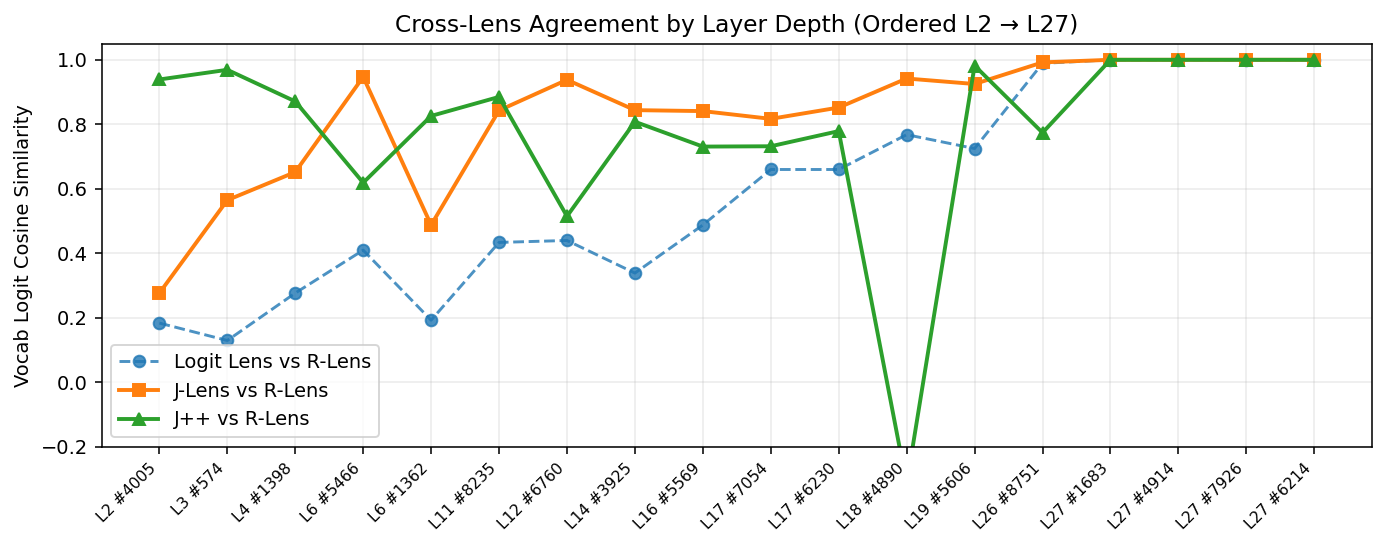

In [8]:
display(Markdown("## 5. Cross-Lens Agreement (Logit Lens vs. J-Lens vs. J++ vs. R-Lens)"))

def topk_jaccard(ln1: str, ln2: str, i: int, k: int = 20, pole: str = "pos") -> float:
    s1 = {tid for tid, _, _ in TOP_K_RECS[ln1][i][pole][:k]}
    s2 = {tid for tid, _, _ in TOP_K_RECS[ln2][i][pole][:k]}
    return len(s1 & s2) / max(len(s1 | s2), 1)

ag_rows = []
for i, s in enumerate(SURVIVORS):
    def lcos(a, b):
        return float(torch.nn.functional.cosine_similarity(LOGITS[a][i], LOGITS[b][i], dim=0))
    ag_rows.append({
        "group": s["group"],
        "neuron": s["label"],
        "layer": s["layer"],
        "cos(LL, J)": round(lcos("logit_lens", "jlens"), 3),
        "cos(LL, R)": round(lcos("logit_lens", "rlens"), 3),
        "cos(J, J++)": round(lcos("jlens", "jpp"), 3),
        "cos(J, R)": round(lcos("jlens", "rlens"), 3),
        "cos(J++, R)": round(lcos("jpp", "rlens"), 3),
        "Jacc20+(J,R)": round(topk_jaccard("jlens", "rlens", i, 20, "pos"), 2),
        "Jacc20+(J++,R)": round(topk_jaccard("jpp", "rlens", i, 20, "pos"), 2),
        "Jacc20-(J++,R)": round(topk_jaccard("jpp", "rlens", i, 20, "neg"), 2),
    })

df_ag = pd.DataFrame(ag_rows).sort_values("layer")
display(df_ag)

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(df_ag))
ax.plot(x, df_ag["cos(LL, R)"], "o--", label="Logit Lens vs R-Lens", alpha=0.8)
ax.plot(x, df_ag["cos(J, R)"], "s-", label="J-Lens vs R-Lens", linewidth=2)
ax.plot(x, df_ag["cos(J++, R)"], "^-", label="J++ vs R-Lens", linewidth=2)
ax.set_xticks(x)
ax.set_xticklabels(df_ag["neuron"], rotation=45, ha="right", fontsize=8)
ax.set_ylabel("Vocab Logit Cosine Similarity")
ax.set_title("Cross-Lens Agreement by Layer Depth (Ordered L2 → L27)")
ax.set_ylim(-0.2, 1.05)
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "cross_lens_agreement.png"), bbox_inches="tight")
plt.show()


=== Key Same-Layer Pairs ===
  L17 #6230  <-> L17 #7054  [Shared L17 pair   ] | raw=+0.009 | LL=+0.008 | J=+0.196 | J++=-0.010 | R=+0.042
  L6 #1362   <-> L6 #5466   [Cross-arm L6      ] | raw=-0.012 | LL=-0.001 | J=+0.015 | J++=+0.024 | R=-0.026
  L27 #4914  <-> L27 #1683  [Cross-arm L27     ] | raw=+0.074 | LL=+0.138 | J=+0.138 | J++=+0.138 | R=+0.138
  L27 #4914  <-> L27 #6214  [Cross-arm L27     ] | raw=+0.123 | LL=+0.079 | J=+0.079 | J++=+0.079 | R=+0.079
  L27 #7926  <-> L27 #1683  [Cross-arm L27     ] | raw=-0.072 | LL=-0.243 | J=-0.243 | J++=-0.243 | R=-0.243
  L27 #7926  <-> L27 #6214  [Cross-arm L27     ] | raw=-0.034 | LL=-0.088 | J=-0.088 | J++=-0.088 | R=-0.088
  L27 #4914  <-> L27 #7926  [Within-R0 L27     ] | raw=+0.103 | LL=-0.097 | J=-0.097 | J++=-0.097 | R=-0.097
  L27 #1683  <-> L27 #6214  [Within-R1 L27     ] | raw=+0.001 | LL=+0.126 | J=+0.126 | J++=+0.126 | R=+0.126

=== Top 10 Strongest Cross-Arm (R0-only <-> R1-only) Pairs in R-Lens Logit Space ===
  L12 #6760  

## 6. 18×18 Cosine Similarity Heatmaps (Raw `down_proj` vs. R-Lens & J++ Logit Space)

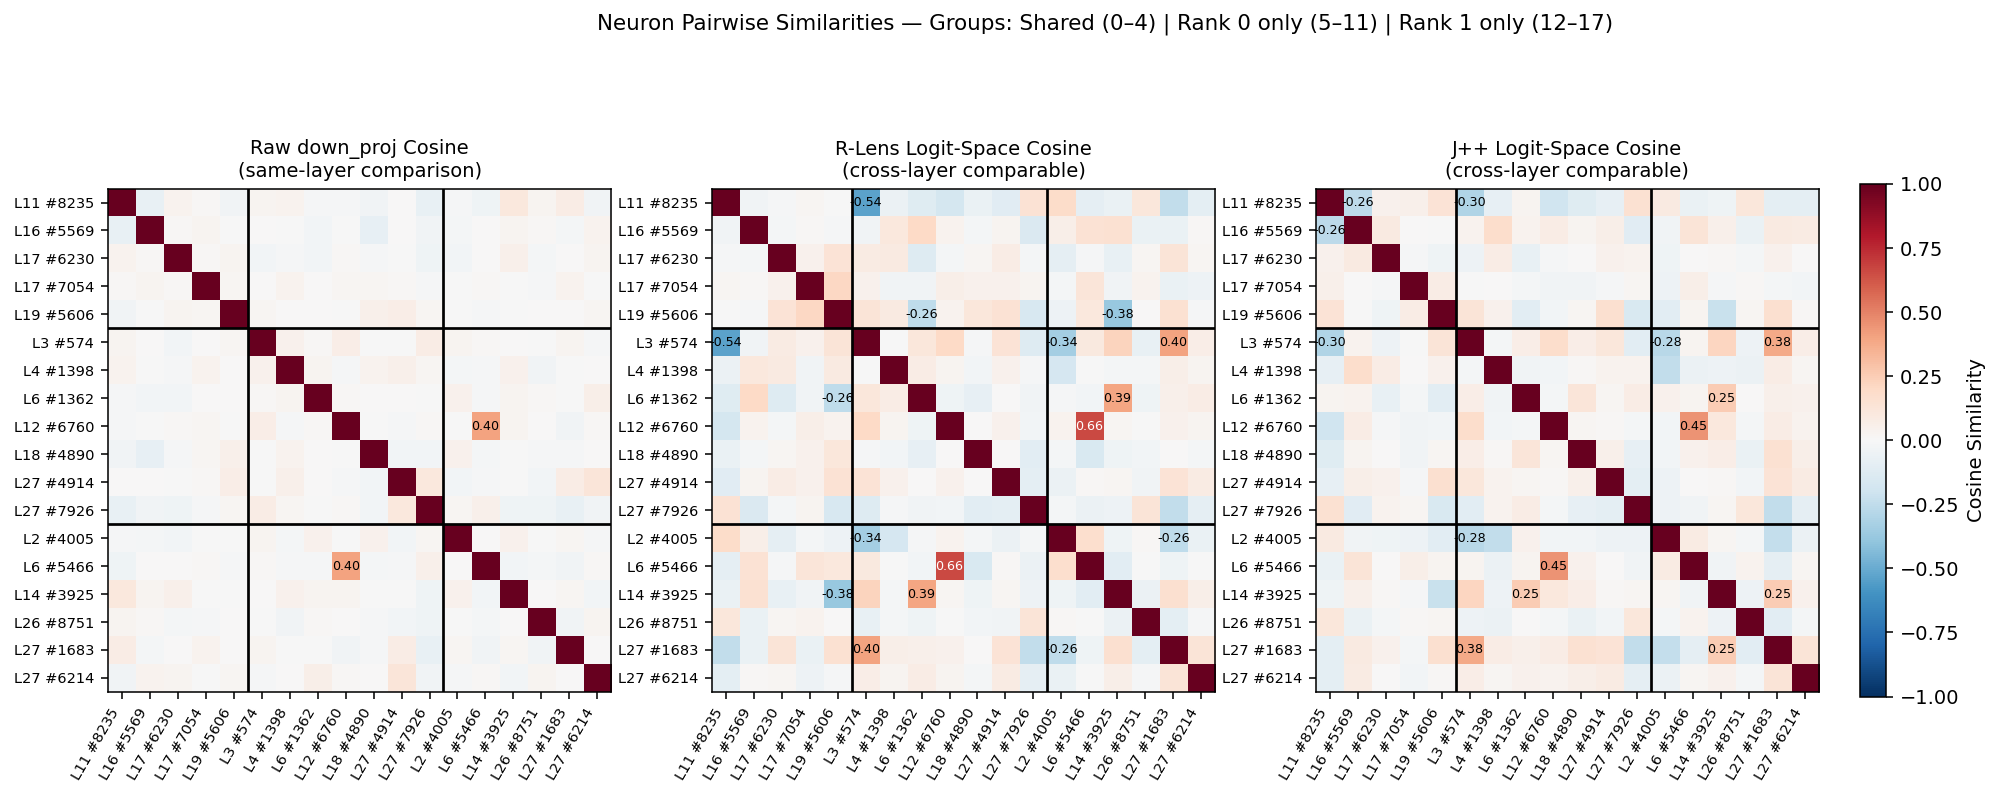

In [9]:
display(Markdown("## 6. 18×18 Cosine Similarity Heatmaps (Raw `down_proj` vs. R-Lens & J++ Logit Space)"))

fig, axes = plt.subplots(1, 3, figsize=(19, 5.8))
panels = [
    ("Raw down_proj Cosine\n(same-layer comparison)", COS_RAW),
    ("R-Lens Logit-Space Cosine\n(cross-layer comparable)", COS_LOGITS["rlens"]),
    ("J++ Logit-Space Cosine\n(cross-layer comparable)", COS_LOGITS["jpp"]),
]

for ax, (title, M) in zip(axes, panels):
    im = ax.imshow(M, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(len(LABELS)))
    ax.set_yticks(range(len(LABELS)))
    ax.set_xticklabels(LABELS, rotation=60, ha="right", fontsize=7.5)
    ax.set_yticklabels(LABELS, fontsize=7.5)
    # Draw group divider lines: Shared (0..4) | R0-only (5..11) | R1-only (12..17)
    for b in [4.5, 11.5]:
        ax.axhline(b, color="black", linewidth=1.4)
        ax.axvline(b, color="black", linewidth=1.4)
    ax.set_title(title, fontsize=10)
    # Annotate notable off-diagonal similarities (|cos| >= 0.25)
    for r in range(len(LABELS)):
        for c in range(len(LABELS)):
            if r != c and abs(M[r, c]) >= 0.25:
                ax.text(c, r, f"{M[r,c]:.2f}", ha="center", va="center", fontsize=6.5,
                        color="white" if abs(M[r, c]) > 0.55 else "black")

cbar = fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.82, pad=0.02)
cbar.set_label("Cosine Similarity")
fig.suptitle("Neuron Pairwise Similarities — Groups: Shared (0–4) | Rank 0 only (5–11) | Rank 1 only (12–17)", y=1.02, fontsize=11)
fig.savefig(os.path.join(FIG_DIR, "cosine_heatmaps_18x18.png"), bbox_inches="tight")
plt.show()

# Focused pair callouts
def print_pair(i, j, tag=""):
    print(f"  {LABELS[i]:10s} <-> {LABELS[j]:10s} [{tag:18s}] | "
          f"raw={COS_RAW[i,j]:+.3f} | LL={COS_LOGITS['logit_lens'][i,j]:+.3f} | "
          f"J={COS_LOGITS['jlens'][i,j]:+.3f} | J++={COS_LOGITS['jpp'][i,j]:+.3f} | R={COS_LOGITS['rlens'][i,j]:+.3f}")

label_to_i = {l: i for i, l in enumerate(LABELS)}
print("=== Key Same-Layer Pairs ===")
print_pair(label_to_i["L17 #6230"], label_to_i["L17 #7054"], "Shared L17 pair")
print_pair(label_to_i["L6 #1362"],  label_to_i["L6 #5466"],  "Cross-arm L6")
for a in ["L27 #4914", "L27 #7926"]:
    for b in ["L27 #1683", "L27 #6214"]:
        print_pair(label_to_i[a], label_to_i[b], "Cross-arm L27")
print_pair(label_to_i["L27 #4914"], label_to_i["L27 #7926"], "Within-R0 L27")
print_pair(label_to_i["L27 #1683"], label_to_i["L27 #6214"], "Within-R1 L27")

print("\n=== Top 10 Strongest Cross-Arm (R0-only <-> R1-only) Pairs in R-Lens Logit Space ===")
cross_pairs = []
for i in IDX_R0_ONLY:
    for j in IDX_R1_ONLY:
        cross_pairs.append((abs(COS_LOGITS["rlens"][i, j]), i, j))
for _, i, j in sorted(cross_pairs, reverse=True)[:10]:
    print_pair(i, j, "R0-only <-> R1-only")

print("\n=== Top 10 Strongest Pairs Overall (Any Group) in R-Lens Logit Space ===")
all_pairs = []
for i in range(len(LABELS)):
    for j in range(i + 1, len(LABELS)):
        all_pairs.append((abs(COS_LOGITS["rlens"][i, j]), i, j))
for _, i, j in sorted(all_pairs, reverse=True)[:10]:
    print_pair(i, j, f"{GROUPS[i]}<->{GROUPS[j]}")


## 7. Targeted Probe: Key GSM8K Gold-Format vs. Qwen-Instruct Style Tokens

Instead of only looking at the top-10 tokens out of 151,936, here we measure the exact **vocab z-score** (`(logit - mean) / std`) of specific GSM8K gold tokens (`####`, `<<`, `>>`, digits `0–9`, `=`, `$`), Qwen2.5-Instruct CoT/markdown/LaTeX tokens (`**`, `###`, `\[`, `boxed`, `Step`, `Therefore`), and stop tokens (`<|im_end|>`, `<|endoftext|>`) across all 18 neurons under **R-Lens** (plus a quick check against Logit Lens & J++).


=== R-Lens Z-Scores across GSM8K / Style / Stop Tokens (|z| >= 2.0 is top/bottom ~2.3% of vocab) ===

=== Strongest Neuron Hits per Target Token (R-Lens, |z| >= 2.0) ===
  ####          : L19 #5606 (+5.70σ), L6 #5466 (+4.05σ), L12 #6760 (+2.97σ)
  <<            : L19 #5606 (+2.94σ), L11 #8235 (+2.94σ), L26 #8751 (+2.52σ), L3 #574 (-2.16σ)
  >>            : L19 #5606 (+2.88σ), L18 #4890 (-2.03σ)
  digits 0-9    : L27 #6214 (-11.76σ), L27 #7926 (+3.11σ), L11 #8235 (+2.28σ), L27 #4914 (-2.09σ)
  =             : L11 #8235 (+3.83σ), L17 #6230 (+2.37σ)
  $             : L27 #6214 (-2.45σ), L19 #5606 (+2.44σ), L17 #7054 (+2.31σ), L6 #1362 (-2.13σ)
  \n            : L18 #4890 (+15.20σ), L6 #5466 (-7.99σ), L6 #1362 (-5.29σ), L14 #3925 (-4.76σ), L16 #5569 (-3.40σ)
  \n\n          : L6 #5466 (+14.91σ), L12 #6760 (+14.81σ), L18 #4890 (+8.62σ), L14 #3925 (-7.35σ), L6 #1362 (-6.57σ)
  ** (bold)     : L19 #5606 (+8.23σ), L14 #3925 (-4.79σ), L16 #5569 (+3.02σ), L6 #5466 (+2.88σ), L2 #4005 (-2.25σ)
  #

,group,####,<<,>>,digits 0-9,=,$,\n,\n\n,** (bold),### (hdr),\[ (LaTeX),boxed,Step,Therefore,So,Final/Ans,<|im_end|>,<|endoftext|>
L11 #8235,shared,0.00,2.94,1.66,2.28,3.83,0.66,1.44,-0.13,-0.19,-0.13,-1.92,-0.39,-0.64,1.07,2.56,0.57,-0.75,-2.27
L16 #5569,shared,-1.14,-0.71,-0.65,-1.02,0.86,0.00,-3.40,-4.36,3.02,-1.08,2.50,-0.18,0.32,-1.77,-1.46,-0.77,0.99,-7.75
L17 #6230,shared,1.06,-0.30,1.93,-0.13,2.37,1.09,-1.82,-1.46,0.81,0.66,1.63,0.98,0.90,0.11,0.66,0.22,-0.14,0.60
L17 #7054,shared,0.45,-0.08,-0.50,0.40,1.65,2.31,-2.33,0.74,2.19,1.67,4.39,-0.57,-0.08,-0.03,-1.14,0.18,0.16,-2.05
L19 #5606,shared,5.70,2.94,2.88,-0.58,1.81,2.44,-2.18,0.14,8.23,4.10,5.99,2.93,0.20,-0.11,-0.56,0.56,-0.50,-2.48
L3 #574,r0_only,1.07,-2.16,-1.63,-1.06,-0.43,-0.08,-2.95,-0.10,-0.40,0.63,3.14,1.10,-0.12,0.84,-1.38,-0.56,0.42,-0.22
L4 #1398,r0_only,1.64,1.38,1.64,0.39,0.89,0.19,0.74,0.75,1.43,0.80,1.46,0.58,0.86,-0.53,0.74,0.24,-0.19,-0.04
L6 #1362,r0_only,-0.90,-0.89,-1.02,-1.66,-1.88,-2.13,-5.29,-6.57,-1.04,-1.70,-1.13,-2.79,-0.18,-2.61,-2.04,-1.32,0.61,-3.64
L12 #6760,r0_only,2.97,-1.86,-1.40,-0.70,-1.09,-1.38,-3.10,14.81,-1.61,1.11,1.59,-0.60,-0.59,-0.90,-0.69,-0.13,-0.17,-5.42
L18 #4890,r0_only,0.06,-0.26,-2.03,-0.06,-0.49,-0.15,15.20,8.62,-1.57,-0.12,-0.45,-0.46,0.16,-0.27,-0.49,-0.76,-0.35,0.75


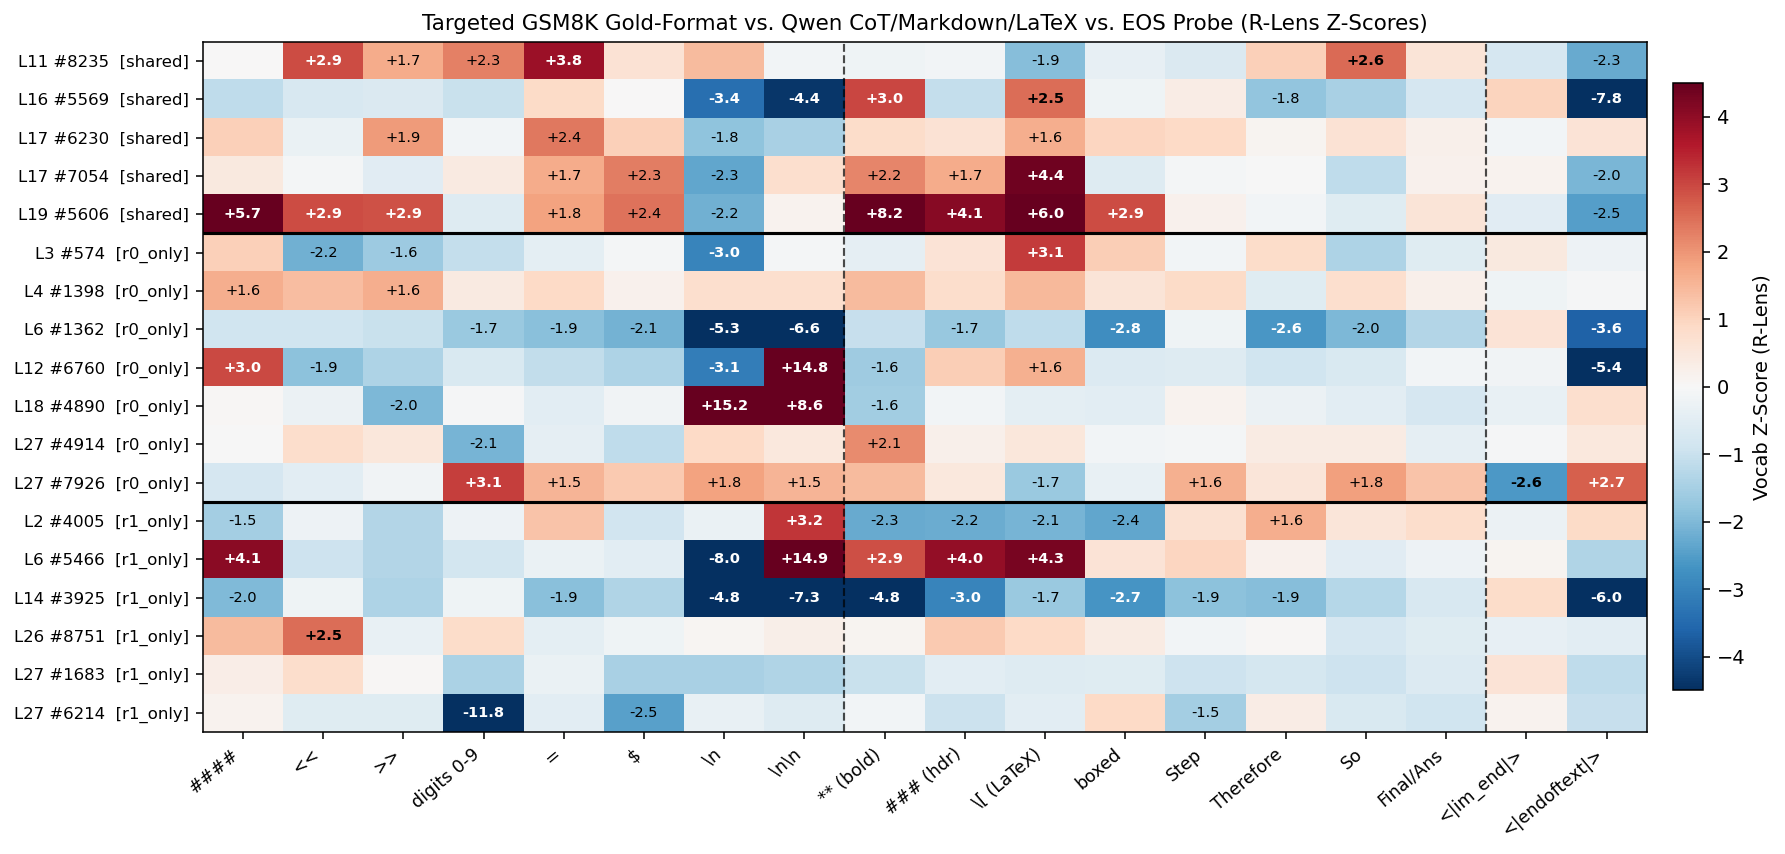

In [10]:
# Map exact strings to token IDs in Qwen2.5's 151,936 vocab
str_to_id = {}
for tid, s in enumerate(ID_TO_STR):
    if s not in str_to_id:
        str_to_id[s] = tid

PROBE_GROUPS = [
    # (display_label, list_of_exact_token_strings_to_average)
    ("####",          ["####", " ####"]),
    ("<<",            ["<<"]),
    (">>",            [">>"]),
    ("digits 0-9",    [str(d) for d in range(10)]),
    ("=",             ["=", " ="]),
    ("$",             ["$", " $"]),
    (r"\n",          ["\n"]),
    (r"\n\n",       ["\n\n"]),
    ("** (bold)",     ["**", " **"]),
    ("### (hdr)",     ["###", "##"]),
    ("\\[ (LaTeX)", ["\\[", "\\("]),
    ("boxed",         ["boxed"]),
    ("Step",          ["Step", " Step"]),
    ("Therefore",     ["Therefore", " Therefore"]),
    ("So",            ["So", " So"]),
    ("Final/Ans",     ["Answer", " Answer", "Final", " Final"]),
    ("<|im_end|>",    ["<|im_end|>"]),
    ("<|endoftext|>", ["<|endoftext|>"]),
]

resolved = []
for name, candidates in PROBE_GROUPS:
    tids = [str_to_id[c] for c in candidates if c in str_to_id]
    if tids:
        resolved.append((name, tids))
    else:
        print(f"Warning: no exact token match for {name} ({candidates})")

def compute_probe_z(lens_name: str) -> pd.DataFrame:
    L = LOGITS[lens_name]  # [18, vocab]
    Z = (L - L.mean(dim=-1, keepdim=True)) / (L.std(dim=-1, keepdim=True) + 1e-8)
    mat = np.zeros((len(LABELS), len(resolved)), dtype=np.float32)
    for col_i, (_, tids) in enumerate(resolved):
        mat[:, col_i] = Z[:, tids].mean(dim=-1).numpy()
    df = pd.DataFrame(mat, index=LABELS, columns=[name for name, _ in resolved])
    df.insert(0, "group", GROUPS)
    return df

df_probe_r = compute_probe_z("rlens")
df_probe_ll = compute_probe_z("logit_lens")

print("=== R-Lens Z-Scores across GSM8K / Style / Stop Tokens (|z| >= 2.0 is top/bottom ~2.3% of vocab) ===")
display(df_probe_r.round(2))

# Plot 18 x 18 targeted probe heatmap (R-Lens)
vals = df_probe_r.drop(columns=["group"]).values
col_names = list(df_probe_r.columns[1:])

fig, ax = plt.subplots(figsize=(14, 6.2))
im = ax.imshow(vals, vmin=-4.5, vmax=4.5, cmap="RdBu_r", aspect="auto")
ax.set_xticks(range(len(col_names)))
ax.set_yticks(range(len(LABELS)))
ax.set_xticklabels(col_names, rotation=40, ha="right", fontsize=9)
ax.set_yticklabels([f"{l}  [{g}]" for l, g in zip(LABELS, GROUPS)], fontsize=8.5)

# Group dividers: Shared (0..4) | R0-only (5..11) | R1-only (12..17)
for b in [4.5, 11.5]:
    ax.axhline(b, color="black", linewidth=1.6)
# Token category dividers: GSM8K gold (0..7) | Qwen CoT/MD/LaTeX (8..15) | Stop (16..17)
for vb in [7.5, 15.5]:
    ax.axvline(vb, color="black", linestyle="--", linewidth=1.1, alpha=0.7)

for r in range(vals.shape[0]):
    for c in range(vals.shape[1]):
        v = vals[r, c]
        if abs(v) >= 1.5:
            ax.text(c, r, f"{v:+.1f}", ha="center", va="center", fontsize=7.5,
                    color="white" if abs(v) > 2.6 else "black", fontweight="bold" if abs(v) >= 2.5 else "normal")

cbar = fig.colorbar(im, ax=ax, shrink=0.88, pad=0.015)
cbar.set_label("Vocab Z-Score (R-Lens)")
ax.set_title("Targeted GSM8K Gold-Format vs. Qwen CoT/Markdown/LaTeX vs. EOS Probe (R-Lens Z-Scores)", fontsize=11)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "gsm8k_token_probe_rlens.png"), bbox_inches="tight")
plt.show()

# Print strongest hits (|z| >= 2.0) per token category
print("\n=== Strongest Neuron Hits per Target Token (R-Lens, |z| >= 2.0) ===")
for col in col_names:
    s = df_probe_r[col]
    hits = [(lbl, float(val)) for lbl, val in s.items() if abs(val) >= 2.0]
    hits.sort(key=lambda x: abs(x[1]), reverse=True)
    if hits:
        hit_str = ", ".join(f"{lbl} ({val:+.2f}σ)" for lbl, val in hits[:5])
        print(f"  {col:14s}: {hit_str}")
    else:
        top_lbl = s.abs().idxmax()
        print(f"  {col:14s}: (max |z| < 2.0; strongest = {top_lbl} {s[top_lbl]:+.2f}σ)")


## 7. (Optional — RunPod / `sl-0` Checkpoints) Activation Shifts $\Delta a_j$ to Pin Down Active Pole (`+v` vs `-v`)

Because SwiGLU activations (`SiLU(gate · x) * (up · x)`) can be positive or negative—and rewiring can either *activate* or *suppress* a neuron—the final step to lock in which pole (`+v` vs `-v`) each arm uses is measuring `mean(Δact_j)` on `val128` using your Rank 0 / Rank 1 checkpoints from `/workspace/neuron-audit/c-attribution/sparse-rewiring-production`.

The cell below auto-skips on your Mac when those checkpoints aren't present, and can be run directly on your GPU box once you copy this notebook over.


In [11]:
RUN_ROOT = "/workspace/neuron-audit/c-attribution/sparse-rewiring-production"
if not os.path.exists(RUN_ROOT):
    print(f"Skipping Stage 4 locally ({RUN_ROOT} not mounted). Run this cell on sl-0 to attach mean Δact signs.")
else:
    print(f"Found {RUN_ROOT}! Ready to load Rank 0 & Rank 1 deltas and compute val128 mean Δact_j per survivor.")


Skipping Stage 4 locally (/workspace/neuron-audit/c-attribution/sparse-rewiring-production not mounted). Run this cell on sl-0 to attach mean Δact signs.
